<div dir="rtl" style="text-align:right">

# تمرين صفّي B2: مراجعات عربية — Embeddings وAraVec وCNN
*تمرين مخبري للجزء **B** ("Embeddings و CNN في Keras"). نفس الخطوات كالواجب المنزلي، لكن ببيانات جديدة.*

</div>

<div dir="rtl" style="text-align:right">

## القصة
تطبيق توصيل طعام في دمشق يتلقى يومياً مراجعات قصيرة كثيرة. المراجعات بالعربية (لهجة سورية والعربية الفصحى)، وبعضها يحتوي على كلمات إنجليزية قليلة. يريد فريق الدعم أداة **تكشف المراجعات السلبية** (التسمية `0`) ليردّ عليها أولاً.

مهمتك: بناء **النماذج نفسها كما في الجزء B** على هذه البيانات الجديدة، ومقارنتها، و**شرح ما تراه**.

⚠️ البيانات **وهمية**: 400 مراجعة قصيرة صُنعت لهذا المخبر. بعض الأشياء فيها **مقصودة**. ابحث عن المفاجآت وفكّر فيها.

## قبل البدء
1. **الملفات** (يشاركها المدرّس): `arabic_food_reviews.csv`. أما نموذج **AraVec** فيُنزَّل تلقائياً من الخلايا في قسم الإعداد. ضع ملف CSV في مجلد اسمه `data` بجانب هذا النوتبوك. *في Colab:* افتح لوحة الملفات (📁)، أنشئ مجلد `data`، وارفع الملف فيه.
2. **افتح نوتبوك الجزء B (للدراسة الذاتية) في تبويب ثانٍ.** في هذا التمرين تنسخ **خلايا من الجزء B** وتغيّر **مدخلاتها**. جدول المرجع أدناه يخبرك أي خلية تنسخ.
3. **المكتبات:** نفس مكتبات الجزء B. إذا لم تكن `gensim` مثبتة، أزل التعليق عن سطر `pip install gensim`.
4. **معالج اللابتوب كافٍ.** كل النماذج صغيرة جداً. كل نموذج يتدرّب في بضع ثوانٍ.

## القواعد
- تبدأ أسماء المتغيرات بـ `ar_` كي لا تختلط مع الجزء B.
- استبدل `...` وأسطر `# TODO`. الخلية التي فيها `...` تعطي خطأ حتى تنهيها. هذا طبيعي.
- شغّل الخلايا من الأعلى إلى الأسفل. إذا بدا شيء خاطئاً، أعد التشغيل من البداية.
- 🤔 **ناقش**: اكتب إجابات قصيرة (1–3 جمل) في خلايا ✏️. نناقشها معاً في نهاية المخبر.
- 💡 **التلميحات** مخفية (انقر ▶). تخبرك *أين تنظر* و*ماذا تغيّر*، لا تعطيك الكود كاملاً. حاول أولاً.

| الرمز | المعنى |
|---|---|
| 📋 | انسخ خلية من الجزء B وغيّرها |
| 🔮 **توقّع** | اكتب تخمينك *قبل* تشغيل الخلية |
| 👀 **لاحظ** | انظر إلى المخرجات |
| 🤔 **ناقش** | فكّر في *السبب* واكتب إجابة قصيرة |
| 💡 | تلميح (مخفي) |
| ⭐ | اختياري، إذا أنهيت مبكراً |

</div>

<div dir="rtl" style="text-align:right">

## 🗺️ جدول المرجع: أي خلية من الجزء B أنسخ؟
«§» تعني **القسم** (Section) في نوتبوك الجزء B. تُسمّى الخلية بسطرها **الأول** (أو بسطر تحتويه).

| الخطوة | مهمتك | 📋 انسخ هذه الخلية من الجزء B | ما الذي تغيّره |
|---|---|---|---|
| **S** | تحميل دوال المساعدة | §1: الخلية التي تبدأ بـ `import matplotlib.pyplot as plt` (`plot_history`)<br>§2: الخلية التي تبدأ بـ `class SimpleTokenizer:`<br>(دالة `create_embedding_matrix` معطاة جاهزة لأنها تستخدم نموذج AraVec) | لا شيء. انسخها وشغّلها كما هي. |
| **0** | النظر إلى البيانات | — (معطاة) | لا شيء. أجب عن السؤال. |
| **1** | تقسيم التدريب/الاختبار + درجة «إيجابي دائماً» | §1: الخلية التي فيها التعليق `# the Yelp sentences, split 75 % / 25 %` (الجزء **الأول**) | استخدم `ar_sentences` و`ar_y`. أبقِ `test_size=0.25` و`random_state=1000`. أسماء جديدة بـ `ar_`. |
| **2** | الخط الأساسي: حقيبة كلمات + الانحدار اللوجستي | نفس خلية §1، الجزء **الثاني** (`# the baseline`) | أسماء `ar_`. النتيجة في `ar_baseline_acc`. |
| **3** | التقطيع والحشو (Padding) | §2: الخلية التي تبدأ بـ `tokenizer = SimpleTokenizer(num_words=5000)`<br>§2: الخلية التي تبدأ بـ `from keras.utils import pad_sequences` | التدريب على `ar_sent_train`. **لا** تستخدم `maxlen = 100`: استخدم أطول تسلسل في بيانات التدريب. |
| **4** | جعل المقطِّع يعمل مع العربية | §2: الخلية التي تبدأ بـ `class SimpleTokenizer:` | اسم الصف الجديد `ArabicTokenizer`. أضف علامات الترقيم العربية `،` `؛` `؟` إلى سلسلة الترقيم. ثم كرر الخطوة 3. |
| **5** | شبكة Embedding + Pooling، واختيار عدد الحقب | §2: خلية النموذج التي فيها `model.add(layers.GlobalMaxPool1D())`<br>§2: خلية التدريب التي تبدأ بـ `history = model.fit(X_train, y_train,` مع `epochs=50`<br>*(نفس النمط كتمرين B، الخطوات 4–5)* | ضع النموذج في دالة `build_ar_model(vocab_size, maxlen)`. 30 حقبة لرؤية المنحنيات، ثم نموذج **جديد** بأفضل عدد من الحقب. |
| **6** | متجهات AraVec المدرّبة مسبقاً، مجمّدة | §3: خلية النموذج التي فيها `trainable=False` وخلية تدريبه | `ar_tokenizer.word_index` و`ar_vocab_size` و`ar_maxlen`. الحجم **100** (حجم AraVec). 30 حقبة تدريب. |
| **7** | الشبكة الالتفافية CNN | §4: خلية النموذج التي فيها `layers.Conv1D(128, 5, activation='relu')`، وخلية تدريبها (`epochs=10`) | Embedding بحجم **100** (لأن AraVec بحجم 100)، و`Conv1D(32, 3)`، ومقاسات `ar_`، و`ar_best_epoch` حقبة. |
| **8** | مقارنة كل النماذج | §6: الخلية التي تبدأ بـ `n_test = len(ar_y_test)` | معطاة هنا. اكتب استنتاجك. |
| **9** | توقّع مراجعات جديدة | §6: الخلية التي تبدأ بـ `new_reviews = [` | `ar_tokenizer` و`ar_maxlen`. استخدم **نموذجين**: التجميع (Pooling) والـ CNN. |
| **⭐** | انظر إلى الأخطاء | §6: الخلية التي تبدأ بـ `probs_test =` | أسماء `ar_`، ونموذج CNN. |

</div>

<div dir="rtl" style="text-align:right">

## الإعداد
شغّل الخلايا التالية بالترتيب. تثبّت المكتبة (إذا لزم)، وتنزّل نموذج AraVec وتفكّ ضغطه داخل `data/`، ثم تستورد المكتبات وتتحقق من وجود الملفات.

</div>

In [67]:
# !pip install gensim

In [68]:
# تنزيل نموذج AraVec (متجهات بطول 100 مدرّبة على تغريدات عربية)
! wget https://archive.org/download/aravec2.0/tweet_cbow_100.zip

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [69]:
# فك ضغط نموذج AraVec داخل مجلد data
!unzip /content/tweet_cbow_100.zip -d data

'unzip' is not recognized as an internal or external command,
operable program or batch file.


In [70]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # يجب ضبطه قبل "import keras"
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import keras
from keras.models import Sequential
from keras import layers
from keras.utils import pad_sequences

DATA_PATH = './data/arabic_food_reviews.csv'
ARAVEC_PATH = './data/tweets_cbow_100'
for p in [DATA_PATH, ARAVEC_PATH]:
    print(('OK       ' if os.path.exists(p) else 'MISSING  ') + p)

OK       ./data/arabic_food_reviews.csv
OK       ./data/tweets_cbow_100


<div dir="rtl" style="text-align:right">

### الخطوة S: دوال المساعدة 📋
انسخ خليتي المساعدة من الجزء B (انظر صف **S** في جدول المرجع) إلى أول خليتين أدناه وشغّلهما. لا تغيّرهما. الخلية الثالثة معطاة جاهزة.

</div>

In [71]:
# 📋 الجزء B، القسم 1: الصق هنا الخلية التي تعرّف plot_history
import matplotlib.pyplot as plt
plt.style.use('ggplot')

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training acc')
    plt.plot(x, val_acc, 'r', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()

In [72]:
# 📋 الجزء B، القسم 2: الصق هنا الخلية التي تعرّف class SimpleTokenizer
class SimpleTokenizer:
    """A small replacement for the old Keras `Tokenizer` (it was removed in Keras 3).
    It turns each word into a whole number. The most frequent word gets 1, the next gets 2, ...
    The number 0 is kept for padding."""

    def __init__(self, num_words=None):
        self.num_words = num_words
        self.word_index = {}      # word -> number
        self.index_word = {}      # number -> word

    @staticmethod
    def _split(text):
        text = text.lower()                                  # lower case
        for ch in '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n':      # remove punctuation
            text = text.replace(ch, ' ')
        return [w for w in text.split(' ') if w]             # split into words

    def fit_on_texts(self, texts):
        counts = {}
        for text in texts:
            for w in self._split(text):
                counts[w] = counts.get(w, 0) + 1
        words = sorted(counts, key=counts.get, reverse=True)  # most frequent word first
        self.word_index = {w: i for i, w in enumerate(words, start=1)}
        self.index_word = {i: w for w, i in self.word_index.items()}

    def texts_to_sequences(self, texts):
        sequences = []
        for text in texts:
            seq = []
            for w in self._split(text):
                i = self.word_index.get(w)
                if i is not None and (self.num_words is None or i < self.num_words):
                    seq.append(i)                            # unknown words are skipped
            sequences.append(seq)
        return sequences

    def sequences_to_texts(self, sequences):
        return [' '.join(self.index_word[i] for i in seq if i in self.index_word) for seq in sequences]

In [73]:
# معطاة: تبني مصفوفة المتجهات من نموذج AraVec (gensim) بدل ملف نصي كما في الجزء B
def create_embedding_matrix(model, word_index, embedding_dim):
    vocab_size = len(word_index) + 1  # الفهرس 0 محجوز
    embedding_matrix = np.zeros((vocab_size, embedding_dim))

    for word, idx in word_index.items():
        if word in model.wv:
            embedding_matrix[idx] = model.wv[word][:embedding_dim]

    return embedding_matrix

<div dir="rtl" style="text-align:right">

## الخطوة 0: النظر إلى البيانات (معطاة)
التسمية `1` = مراجعة إيجابية، والتسمية `0` = مراجعة سلبية.

</div>

In [74]:
# قراءة الملف وفصل النصوص عن التسميات
df_ar = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
ar_sentences = df_ar['review'].values
ar_y = df_ar['label'].values

print("number of reviews:", len(ar_sentences))
print("label counts (0 = negative, 1 = positive):", {0: int((ar_y == 0).sum()), 1: int((ar_y == 1).sum())})
print("words per review: min {}, mean {:.1f}, max {}".format(
    min(len(s.split()) for s in ar_sentences),
    np.mean([len(s.split()) for s in ar_sentences]),
    max(len(s.split()) for s in ar_sentences)))
for label, text in list(zip(ar_y, ar_sentences))[:8]:
    print(label, "|", text)

number of reviews: 400
label counts (0 = negative, 1 = positive): {0: 140, 1: 260}
words per review: min 3, mean 9.2, max 19
1 | المندوب محترم ولطيف والخدمة ممتازة
0 | بصراحة الأكل بارد. للأسف!
1 | الدفع cash عند الباب مريح، الطعم متل أكل البيت. أكيد رح أطلب مرة تانية!
1 | الخدمة ممتازة و وصل الطلب خلال 20 دقيقة. تسلم إيدكم
1 | طلبت اليوم والاكل طيب كتير و كل شي ok، الله يعطيكم العافية
0 | الأكل ما كان لذيذ
0 | وصل الطلب قبل الوقت لكن الفروج مو مستوي.
1 | دفعت أونلاين، الطلب وصل كامل، خدمة العملاء ردوا بسرعة، أنصح فيه!


<div dir="rtl" style="text-align:right">

#### 🤔 ناقش 0
1. هل الصنفان بالحجم نفسه؟ (في بيانات Yelp في الجزء B كانت 50 % / 50 %.)
2. تخيّل «نموذجاً» لا يقرأ النص و**يقول دائماً إيجابي**. ما الدقة التي سيحصل عليها تقريباً؟
3. قارن المراجعات بجمل Yelp. اكتب شيئين **مختلفين** في هذا النص.

**✏️ إجاباتك:**

</div>

 لا 65% ايجابي و 35 سلبي

 65%

 مزج اللغة العربية والانكليزية 

<div dir="rtl" style="text-align:right">

## الخطوة 1: تقسيم البيانات 📋
قسّم `ar_sentences` و`ar_y` إلى 75 % بيانات تدريب و25 % بيانات اختبار، مع `random_state=1000`. ثم احسب `ar_majority_acc`: دقة **الاختبار** لنموذج يقول دائماً `1`.
<details>
<summary><b>💡 تلميح 1</b></summary>

جدول المرجع، الصف 1. تُرجع الدالة أربعة أشياء: جمل التدريب، جمل الاختبار، تسميات التدريب، تسميات الاختبار. لـ `ar_majority_acc`: التسميات 0 و1، لذلك **المتوسط** لتسميات الاختبار هو نسبة المراجعات الإيجابية.

</details>

</div>

In [75]:
import random

from sklearn.model_selection import train_test_split

# TODO: استبدل ... باستدعاء train_test_split
ar_sent_train, ar_sent_test, ar_y_train, ar_y_test = train_test_split(ar_sentences, ar_y, random_state=1000 , test_size=0.25)

ar_majority_acc = sum(ar_y_test)/ len(ar_y_test)     # TODO: دقة الاختبار لنموذج «إيجابي دائماً»

print(len(ar_sent_train), "training reviews,", len(ar_sent_test), "test reviews")
print("always-positive test accuracy:", ar_majority_acc)

300 training reviews, 100 test reviews
always-positive test accuracy: 0.66


<div dir="rtl" style="text-align:right">

## الخطوة 2: الخط الأساسي 📋
حقيبة كلمات (`CountVectorizer`) + `LogisticRegression`. سمِّ المحوّل `ar_vectorizer`. يأتي المفردات **فقط** من مراجعات التدريب. احفظ دقة الاختبار في `ar_baseline_acc`.
<details>
<summary><b>💡 تلميح 2</b></summary>

جدول المرجع، الصف 2. الترتيب: أنشئ المحوّل ← `fit` على مراجعات التدريب ← أنشئ المصنّف و`fit` له على مراجعات التدريب **المحوّلة** ← `score` على مراجعات الاختبار **المحوّلة**.

</details>

</div>

In [76]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

# TODO 2a: أنشئ ar_vectorizer ودرّبه (fit)
# TODO 2b: أنشئ المصنّف ودرّبه
# ar_baseline_acc = ...      # TODO 2c: دقة الاختبار
ar_vectorizer = CountVectorizer()
ar_vectorizer.fit(ar_sent_train)
ar_clf = LogisticRegression()
ar_clf.fit(ar_vectorizer.transform(ar_sent_train), ar_y_train)
ar_baseline_acc = ar_clf.score(ar_vectorizer.transform(ar_sent_test), ar_y_test)
print("Baseline test accuracy: {:.4f}".format(ar_baseline_acc))
# print("Baseline test accuracy: {:.4f}".format(ar_baseline_acc))

Baseline test accuracy: 0.8500


<div dir="rtl" style="text-align:right">

## الخطوة 3: التقطيع والحشو 📋
1. أنشئ `ar_tokenizer = SimpleTokenizer(num_words=5000)` ودرّبه على مراجعات **التدريب**. أنشئ `ar_seq_train` و`ar_seq_test`.
2. احسب `ar_vocab_size` (تذكّر `+ 1`).
3. `ar_maxlen` = طول **أطول تسلسل تدريب** (المراجعات قصيرة؛ 100 طويل جداً).
4. الحشو: `ar_X_train` و`ar_X_test`، مع `padding='post'`.
<details>
<summary><b>💡 تلميح 3</b></summary>

جدول المرجع، الصف 3: خليتان من القسم 2. غيّر جمل الإدخال وأسماء المتغيرات. لأطول تسلسل تحتاج إلى *طول* كل قائمة في `ar_seq_train`، ثم القيمة العظمى (فعلت هذا في التمرين B).

</details>

</div>

In [77]:
# TODO 3a: ar_tokenizer -> ar_seq_train, ar_seq_test
# ar_vocab_size = ...        # TODO 3b
# ar_maxlen = ...            # TODO 3c
# TODO 3d: الحشو -> ar_X_train, ar_X_test

from keras.utils import pad_sequences

ar_tokenizer = SimpleTokenizer(num_words=5000)
ar_tokenizer.fit_on_texts(ar_sent_train)
ar_seq_train = ar_tokenizer.texts_to_sequences(ar_sent_train)
ar_seq_test = ar_tokenizer.texts_to_sequences(ar_sent_test)

ar_vocab_size = len(ar_tokenizer.word_index) + 1
ar_maxlen = max(len(s) for s in ar_seq_train)

ar_X_train = pad_sequences(ar_seq_train, padding='post', maxlen=ar_maxlen)
ar_X_test = pad_sequences(ar_seq_test, padding='post', maxlen=ar_maxlen)
print("vocab size:", ar_vocab_size, " maxlen:", ar_maxlen, " train shape:", ar_X_train.shape)
# print("vocab size:", ar_vocab_size, " maxlen:", ar_maxlen, " train shape:", ar_X_train.shape)

vocab size: 370  maxlen: 19  train shape: (300, 19)


<div dir="rtl" style="text-align:right">

#### 👀 لاحظ (معطى)
قارن المفردتين، وانظر إلى بعض «الكلمات» التي أنتجها المقطِّع.

</div>

In [78]:
ar_vocab_size_before = ar_vocab_size          # احتفظ بهذا الرقم للخطوة 4
print("CountVectorizer words:", len(ar_vectorizer.vocabulary_))
print("SimpleTokenizer words:", ar_vocab_size - 1)

# الكلمات التي تنتهي بعلامة ترقيم عربية
strange = [w for w in ar_tokenizer.word_index if w[-1] in '،؛؟']
print(len(strange), "tokenizer words end with Arabic punctuation, for example:", strange[:8])
w = strange[0]
print("example:", repr(w), "has number", ar_tokenizer.word_index[w],
      " but", repr(w[:-1]), "has number", ar_tokenizer.word_index.get(w[:-1]))

CountVectorizer words: 299
SimpleTokenizer words: 369
77 tokenizer words end with Arabic punctuation, for example: ['بصراحة،', 'والله،', 'وطيبة،', 'صراحة،', 'هالمطعم،', 'ونظيف،', 'سريع،', 'رائعة،']
example: 'بصراحة،' has number 33  but 'بصراحة' has number 40


<div dir="rtl" style="text-align:right">

#### 🤔 ناقش 3
1. في الجزء B كان الرقمان قريبين (1714 و1746). هنا الفرق أكبر بكثير. لماذا؟ انظر إلى القائمة.
2. بالنسبة للنموذج، `بصراحة` و`بصراحة،` كلمتان **مختلفتان** لهما متجهان مختلفان. لماذا هذا سيئ، خاصة مع 300 مراجعة تدريب فقط؟
3. أي سطر في `SimpleTokenizer` هو المسؤول؟ (كُتب للنصوص الإنجليزية.)

**✏️ إجاباتك:**

</div>

<div dir="rtl" style="text-align:right">

## الخطوة 4: جعل المقطِّع يعمل مع العربية 📋
1. انسخ صف `SimpleTokenizer` إلى الخلية أدناه. غيّر **اسمه** إلى `ArabicTokenizer`، وأضف علامات الترقيم العربية الثلاث `،؛؟` إلى سلسلة الترقيم. لا تغيّر أي شيء آخر.
2. في الخلية التالية، **كرر الخطوة 3** باستخدام `ArabicTokenizer` (أسماء المتغيرات نفسها، فتحل القيم الجديدة محل القديمة).
<details>
<summary><b>💡 تلميح 4</b></summary>

ابحث عن السطر الذي فيه التعليق `# remove punctuation`. الأحرف داخل سلسلة Python عادية، فيمكنك كتابة (أو نسخ) `،؛؟` في آخر السلسلة، قبل `'` الإغلاقية. للخلية الثانية: انسخ كود الخطوة 3 **الخاص بك** وغيّر اسم الصف فقط.

</details>

</div>

In [79]:
# 📋 الصق هنا صف SimpleTokenizer، وغيّر اسمه إلى ArabicTokenizer، وأضف ،؛؟
class ArabicTokenizer:
    """A small replacement for the old Keras `Tokenizer` (it was removed in Keras 3).
    It turns each word into a whole number. The most frequent word gets 1, the next gets 2, ...
    The number 0 is kept for padding."""

    def __init__(self, num_words=None):
        self.num_words = num_words
        self.word_index = {}      # word -> number
        self.index_word = {}      # number -> word

    @staticmethod
    def _split(text):
        text = text.lower()                                  # lower case
        for ch in '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~؟؛،\t\n':      # remove punctuation
            text = text.replace(ch, ' ')
        return [w for w in text.split(' ') if w]             # split into words

    def fit_on_texts(self, texts):
        counts = {}
        for text in texts:
            for w in self._split(text):
                counts[w] = counts.get(w, 0) + 1
        words = sorted(counts, key=counts.get, reverse=True)  # most frequent word first
        self.word_index = {w: i for i, w in enumerate(words, start=1)}
        self.index_word = {i: w for w, i in self.word_index.items()}

    def texts_to_sequences(self, texts):
        sequences = []
        for text in texts:
            seq = []
            for w in self._split(text):
                i = self.word_index.get(w)
                if i is not None and (self.num_words is None or i < self.num_words):
                    seq.append(i)                            # unknown words are skipped
            sequences.append(seq)
        return sequences

    def sequences_to_texts(self, sequences):
        return [' '.join(self.index_word[i] for i in seq if i in self.index_word) for seq in sequences]

In [80]:
# TODO: كرر الخطوة 3، الآن مع ArabicTokenizer
# ar_tokenizer = ...
# ...

ar_tokenizer = ArabicTokenizer(num_words=5000)
ar_tokenizer.fit_on_texts(ar_sent_train)
ar_seq_train = ar_tokenizer.texts_to_sequences(ar_sent_train)
ar_seq_test = ar_tokenizer.texts_to_sequences(ar_sent_test)

ar_vocab_size = len(ar_tokenizer.word_index) + 1
ar_maxlen = max(len(s) for s in ar_seq_train)

ar_X_train = pad_sequences(ar_seq_train, padding='post', maxlen=ar_maxlen)
ar_X_test = pad_sequences(ar_seq_test, padding='post', maxlen=ar_maxlen)
print("vocab size:", ar_vocab_size, " maxlen:", ar_maxlen, " train shape:", ar_X_train.shape)
print("vocab size before:", ar_vocab_size_before, " after:", ar_vocab_size, " maxlen:", ar_maxlen)
print("words with Arabic punctuation now:", sum(w[-1] in '،؛؟' for w in ar_tokenizer.word_index))

vocab size: 301  maxlen: 19  train shape: (300, 19)
vocab size before: 370  after: 301  maxlen: 19
words with Arabic punctuation now: 0


<div dir="rtl" style="text-align:right">

#### 👀 لاحظ (معطى)
علامات الترقيم صُحّحت. لكن انظر إلى كل «الكلمات» التي تحتوي على *الأكل* (`أكل` / `اكل`):

</div>

In [81]:
print([w for w in ar_tokenizer.word_index if 'أكل' in w or 'اكل' in w])

['الأكل', 'والأكل', 'أكل', 'بالأكل', 'الاكل', 'بالاكل', 'والاكل']


<div dir="rtl" style="text-align:right">

#### 🤔 ناقش 4
كم «كلمة» مختلفة ترى للفكرة نفسها؟ اذكر **سببين** لكثرة أشكال الكلمة في العربية. (فكّر في الحروف الملتصقة بالكلمة، وفي طريقة كتابة الناس لـ `أ` على الإنترنت.)

**✏️ إجابتك:**

</div>

<div dir="rtl" style="text-align:right">

## الخطوة 5: شبكة Embedding + Pooling 📋
1. اكتب دالة `build_ar_model(vocab_size, maxlen)` تُرجع نموذجاً **مترجَماً (compiled)**:
   `Input` ← `Embedding(output_dim=50)` ← `GlobalMaxPool1D` ← `Dense(10, relu)` ← `Dense(1, sigmoid)`، مع `adam` و`binary_crossentropy` و`accuracy`.
2. درّب نموذجاً واحداً لـ **30 حقبة** (`validation_split=0.2`، `batch_size=10`) وارسم المنحنيات.
3. `ar_best_epoch` = الحقبة ذات **أقل خسارة تحقق (validation loss)**.
4. ابنِ نموذجاً **جديداً**، درّبه لـ `ar_best_epoch` حقبة، واحفظ دقة الاختبار في `ar_nn_acc`. سمِّ هذا النموذج `ar_final_model`.

#### 🔮 توقّع
كم معاملاً (Parameter) ستحتوي طبقة **Embedding** الآن؟ (في الجزء B كانت 1747 × 50 = 87,350.) اكتب رقمك، ثم تحقق منه في الملخص.

**✏️ تخمينك:**
<details>
<summary><b>💡 تلميح 5</b></summary>

جدول المرجع، الصف 5. الطبقات هي نفسها في نموذج التجميع من القسم 2؛ ضعها داخل `def` وأضف `return`. الطبقة الأولى هي `layers.Input(shape=(maxlen,), dtype='int32')`. لأفضل حقبة: `history.history['val_loss']` قائمة فيها رقم لكل حقبة. تعطي `np.argmin` *الموضع*، والمواضع تبدأ من 0 والحقب من 1. تُرجع `model.evaluate(...)` القيمة `[loss, accuracy]`.

</details>

</div>

In [82]:
from keras.models import Sequential
from keras import layers

def build_ar_model(vocab_size, maxlen):
    m = Sequential()
    m.add(layers.Input(shape=(maxlen,), dtype='int32'))
    m.add(layers.Embedding(input_dim=vocab_size, output_dim=50))
    m.add(layers.GlobalMaxPool1D())
    m.add(layers.Dense(10, activation='relu'))
    m.add(layers.Dense(1, activation='sigmoid'))
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return m

build_ar_model(ar_vocab_size, ar_maxlen).summary()   # عرض بنية النموذج وعدد المعاملات

Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_18 (Embedding)        │ (None, 19, 50)         │        15,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_17         │ (None, 50)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,571 (60.82 KB)

 Trainable params: 15,571 (60.82 KB)

 Non-trainable params: 0 (0.00 B)

best epoch: 14
Embedding + pooling test accuracy: 0.8600


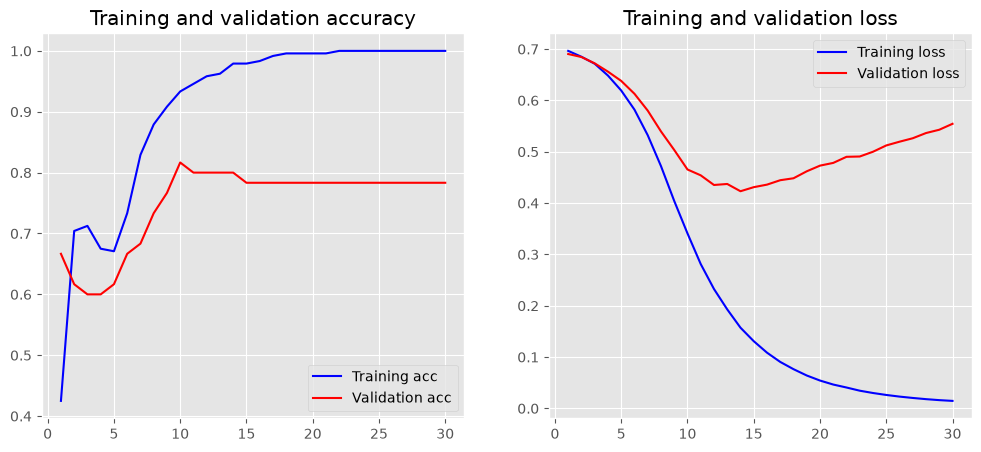

In [83]:
# TODO 5a: ابنِ نموذجاً ودرّبه 30 حقبة، واحتفظ بـ history، وارسمه بـ plot_history


import numpy as np

ar_model = build_ar_model(ar_vocab_size, ar_maxlen)
ar_history = ar_model.fit(ar_X_train, ar_y_train, epochs=30, verbose=False,
                          validation_split=0.2, batch_size=10)
plot_history(ar_history)

ar_best_epoch = int(np.argmin(ar_history.history['val_loss'])) + 1
print("best epoch:", ar_best_epoch)

ar_final_model = build_ar_model(ar_vocab_size, ar_maxlen)       # NEW model, new random weights
ar_final_model.fit(ar_X_train, ar_y_train, epochs=ar_best_epoch, verbose=False,
                   validation_split=0.2, batch_size=10)
ar_nn_acc = ar_final_model.evaluate(ar_X_test, ar_y_test, verbose=False)[1]
print("Embedding + pooling test accuracy: {:.4f}".format(ar_nn_acc))

<div dir="rtl" style="text-align:right">

#### 🤔 ناقش 5
1. انظر إلى المنحنيات. بعد أي حقبة يبدأ النموذج بالإفراط في التخصيص (Overfitting)؟ كيف تراه؟
2. لماذا يجب أن يكون النموذج النهائي **جديداً**، وليس النموذج نفسه بعد تدريبه مرة أخرى؟

**✏️ إجاباتك:**

</div>

<div dir="rtl" style="text-align:right">

## الخطوة 6: متجهات AraVec المدرّبة مسبقاً (مجمّدة) 📋
في الواجب المنزلي، غطّى GloVe نحو **95 %** من مفردات Yelp الإنجليزية. هنا نستخدم **نموذج AraVec** (`tweets_cbow_100`)، المدرَّب على تغريدات عربية، بمتجهات بطول **100**. الهدف: معرفة مقدار تغطية مفرداتنا العربية.

#### 🔮 توقّع
ما نسبة التغطية التي تتوقعها هنا؟ اكتب رقماً قبل تشغيل الخلية.

**✏️ تخمينك:**

1. أنشئ `ar_embedding_matrix` باستخدام `create_embedding_matrix(aravec_model, ...)`، بـ 100 بُعد، من `ar_tokenizer.word_index`.
2. احسب نسبة التغطية `ar_coverage` (نسبة الصفوف التي ليست كلها أصفاراً).
<details>
<summary><b>💡 تلميح 6أ</b></summary>

استخدم `aravec_model` (محمَّل في أول الخلية)، و`ar_tokenizer.word_index`، والبُعد 100. للتغطية: عدّ الصفوف التي فيها قيمة غير صفرية (`np.count_nonzero(..., axis=1)`) ثم اقسم على `ar_vocab_size`. تحميل النموذج يأخذ بضع ثوانٍ.

</details>

</div>

In [84]:
import gensim

# تحميل نموذج Word2Vec المدرّب مسبقاً (AraVec)
aravec_model = gensim.models.Word2Vec.load(ARAVEC_PATH)

# TODO 6a: ar_embedding_matrix = create_embedding_matrix(...)
embedding_dim = 50
ar_embedding_matrix = create_embedding_matrix(
    aravec_model,
    ar_tokenizer.word_index, embedding_dim)
nonzero_elements = np.count_nonzero(np.count_nonzero(ar_embedding_matrix, axis=1))

ar_coverage = nonzero_elements / ar_vocab_size          # TODO 6b
print("AraVec coverage: {:.1%}".format(ar_coverage))

# معطى: أي كلماتنا لها متجه في AraVec؟
covered = [w for w, i in ar_tokenizer.word_index.items() if ar_embedding_matrix[i].any()]
print(len(covered), "words have an AraVec vector:", covered)

AraVec coverage: 59.5%
179 words have an AraVec vector: ['طلبت', 'الطلب', 'كان', 'التطبيق', 'وصل', 'ما', 'مو', 'من', 'بطلب', 'كتير', 'تاني', 'اليوم', 'والله', 'كل', 'عن', 'طريق', 'فيه', 'رقم', 'و', 'عشا', 'التوصيل', 'سريع', 'باسم', 'رح', 'شي', 'ونظيف', 'التغليف', 'بس', 'مرتب', 'بجرب', 'شوي', 'يعطيكم', 'لذيذ', 'لكن', 'متل', 'كامل', 'السعر', 'محترم', 'معقول', 'طازج', 'هالمطعم', 'سيء', 'وطلبت', 'المندوب', 'مستوي', 'البيتزا', 'بارد', 'الطعام', 'وصلت', 'ولطيف', 'الطعم', 'تسلم', 'فرع', 'سخن', 'الفروج', 'تمام', 'قبل', 'البرغر', 'بيعلق', 'مشاوي', 'غلط', 'والطلب', 'سهل', 'دفعت', 'المتوقع', 'غالي', 'شاورما', 'وبطاطا', 'والبيتزا', 'والتطبيق', 'وسريع', 'الوقت', 'العيد', 'خيارات', 'والصوص', 'رائع', 'البيت', 'والسعر', 'عم', 'مضبوط', 'كانت', 'والتوصيل', 'انحلت', 'لليوم', 'نجوم', 'والدفع', 'عند', 'الباب', 'مريح', 'والطعم', 'بنصح', 'بالوقت', 'ناقص', 'الدفع', 'بدي', 'وقت', 'الغدا', 'الشاورما', 'بتجنن', 'الفلافل', 'الله', 'الاكل', 'خلال', 'مش', 'طلع', 'شو', 'يصير', 'ولا', 'طيب', 'والمندوب', 'بطيء', 'ودفع

<div dir="rtl" style="text-align:right">

3. ابنِ نموذج **AraVec المجمّد** (`trainable=False`)، وهو النموذج نفسه من القسم 3 ولكن بمقاساتنا. سمِّه `ar_aravec_model`. درّبه لـ **30 حقبة** واحفظ دقة الاختبار في `ar_aravec_acc`.
<details>
<summary><b>💡 تلميح 6ب</b></summary>

انسخ خلية نموذج القسم 3 التي فيها `trainable=False` وخلية تدريبها. التغييرات: `vocab_size` ← `ar_vocab_size`، و`maxlen` ← `ar_maxlen`، و`embedding_dim` ← 100، و`embedding_matrix` ← `ar_embedding_matrix`، والبيانات ← `ar_X_train`، `ar_y_train`، `ar_X_test`، `ar_y_test`.

</details>

</div>

In [85]:
# TODO 6c: ابنِ ar_aravec_model (AraVec مجمّد) وترجمه ودرّبه 30 حقبة
ar_aravec_model = Sequential()
ar_aravec_model.add(layers.Input(shape=(ar_maxlen,), dtype='int32'))
ar_aravec_model.add(layers.Embedding(ar_vocab_size, embedding_dim,
                           embeddings_initializer=keras.initializers.Constant(ar_embedding_matrix),
                           trainable=False))
ar_aravec_model.add(layers.GlobalMaxPool1D())
ar_aravec_model.add(layers.Dense(10, activation='relu'))
ar_aravec_model.add(layers.Dense(1, activation='sigmoid'))
ar_aravec_model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
history = ar_aravec_model.fit(ar_X_train, ar_y_train,
                    epochs=30,
                    verbose=False,
                    validation_split = 0.2,
                    batch_size=10)
loss, accuracy = ar_aravec_model.evaluate(ar_X_train, ar_y_train, verbose=False)
ar_aravec_acc = accuracy         # TODO 6d: دقة الاختبار
print("Frozen AraVec test accuracy: {:.4f}".format(ar_aravec_acc))

# معطى: ماذا يتوقع هذا النموذج؟
ar_aravec_pred = ar_aravec_model.predict(ar_X_test, verbose=0).ravel() > 0.5
print("share of test reviews predicted positive: {:.2f}".format(ar_aravec_pred.mean()))
print("always-positive test accuracy:            {:.2f}".format(ar_majority_acc))

Frozen AraVec test accuracy: 0.7733
share of test reviews predicted positive: 0.71
always-positive test accuracy:            0.66


<div dir="rtl" style="text-align:right">

#### 🤔 ناقش 6
1. لماذا التغطية هنا مختلفة عن الجزء B (95 %)؟ ما نوع الكلمات التي حصلت على متجه؟ وأيها لم يحصل عليه؟
2. قد تبدو الدقة «ليست سيئة». قارنها بدقة «إيجابي دائماً». ماذا تعلّم هذا النموذج فعلاً؟ ولماذا تقريباً أغلب توقعاته إيجابية؟
3. قارن دقة AraVec المجمّد بالخط الأساسي. لماذا قد تكون أقل رغم أن المتجهات مدرّبة على العربية؟ (فكّر في الكلمات التي لا متجه لها، وفي أن المتجهات عامة وليست مدرّبة على تقييم المطاعم، وفي تجميد الطبقة.)
4. ماذا تحتاج لاستخدام المتجهات المدرّبة مسبقاً **بشكل جيد** في هذه المهمة؟

**✏️ إجاباتك:**

</div>

<div dir="rtl" style="text-align:right">

## الخطوة 7: شبكة CNN صغيرة 📋
ابنِ `ar_cnn`: `Input` ← `Embedding(ar_vocab_size, 100)` ← `Conv1D(32, 3, activation='relu')` ← `GlobalMaxPooling1D` ← `Dense(10, relu)` ← `Dense(1, sigmoid)`. (أصغر من الجزء B: 32 مرشِّحاً، ونوافذ من 3 كلمات.) درّبه لـ `ar_best_epoch` حقبة واحفظ دقة الاختبار في `ar_cnn_acc`.

#### 🔮 توقّع
(أ) شكل مخرجات `Conv1D` (طول الدخل هو `ar_maxlen`). (ب) عدد معاملاته. استخدم الصيغة من القسم 4. (تذكّر أن بُعد Embedding هنا هو **100**.)

**✏️ تخمينك:**
<details>
<summary><b>💡 تلميح 7</b></summary>

جدول المرجع، الصف 7. ابدأ من خلية CNN في القسم 4. غيّر `embedding_dim` إلى 100، والأرقام في `Conv1D(...)`، وشكل `Input`، والـ `epochs` في خلية التدريب. لسؤال التوقع: طول المخرجات = طول الدخل − حجم النافذة + 1؛ المعاملات = (حجم النافذة × بُعد Embedding + 1) × عدد المرشحات.

</details>

</div>

In [86]:
# TODO 7a: ابنِ ar_cnn وترجمه واعرض summary() ودرّبه
cnn = Sequential()
cnn.add(layers.Input(shape=(ar_maxlen,), dtype='int32'))
cnn.add(layers.Embedding(ar_vocab_size, 100))
cnn.add(layers.Conv1D(32, 3, activation='relu'))
cnn.add(layers.GlobalMaxPooling1D())
cnn.add(layers.Dense(10, activation='relu'))
cnn.add(layers.Dense(1, activation='sigmoid'))
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.fit(ar_X_train, ar_y_train, epochs=ar_best_epoch, verbose=False, validation_split=0.2, batch_size=10)
ar_cnn_acc = cnn.evaluate(ar_X_test, ar_y_test, verbose=False)[1]           # TODO 7b: دقة الاختبار
print("CNN test accuracy: {:.4f}".format(ar_cnn_acc))
cnn.summary()

CNN test accuracy: 0.8700


Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_22 (Embedding)        │ (None, 19, 100)        │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 17, 32)         │         9,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_21         │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 10)             │           330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,221 (469.62 KB)

 Trainable params: 40,073 (156.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 80,148 (313.08 KB)

<div dir="rtl" style="text-align:right">

## الخطوة 8: المقارنة (معطاة) والاستنتاج

</div>

In [87]:
# مقارنة كل النماذج على مجموعة الاختبار نفسها
n_test = len(ar_y_test)
results = {"always positive":        ar_majority_acc,
           "baseline (BoW + LR)":    ar_baseline_acc,
           "Embedding + pooling":    ar_nn_acc,
           "AraVec (frozen)":        ar_aravec_acc,
           "CNN":                    ar_cnn_acc}
for name, acc in results.items():
    print("{:24s} {:.3f}   = {:3.0f} of {} test reviews correct".format(name, acc, acc * n_test, n_test))

always positive          0.660   =  66 of 100 test reviews correct
baseline (BoW + LR)      0.850   =  85 of 100 test reviews correct
Embedding + pooling      0.860   =  86 of 100 test reviews correct
AraVec (frozen)          0.773   =  77 of 100 test reviews correct
CNN                      0.870   =  87 of 100 test reviews correct


<div dir="rtl" style="text-align:right">

#### ✍️ استنتاجك (3–4 جمل)
أي نموذج هو الأفضل؟ بكم **مراجعة** يتفوق على الخط الأساسي؟ هل تثق بهذا الفرق (فكّر في حجم مجموعة الاختبار، وفي الأوزان العشوائية الابتدائية)؟ أي نموذج تعطيه لفريق الدعم، ولماذا؟

**✏️ استنتاجك:**

</div>

<div dir="rtl" style="text-align:right">

## الخطوة 9: مراجعات جديدة 📋
القائمة تحتوي على **أزواج**: الكلمات نفسها، لكن المعنى يتغير بسبب كلمة نفي (`مو` / `ما` = لا) أو `بس` (لكن). توقّع كل مراجعة بـ **النموذجين**: `ar_final_model` (التجميع) و`ar_cnn`. أضف مراجعة واحدة من عندك.
<details>
<summary><b>💡 تلميح 9</b></summary>

جدول المرجع، الصف 9. النص الجديد يستخدم **المقطِّع نفسه** (بدون `fit` جديد) و`maxlen` نفسه. ثم استدعِ `predict` مرتين، مرة لكل نموذج. تجعل `.ravel()` النتيجة مسطحة. اطبع الاحتمالين والمراجعة في سطر واحد.

</details>

</div>

In [88]:
new_reviews = [
    "الأكل طيب كتير",
    "الأكل مو طيب أبداً",
    "التوصيل تأخر ساعة",
    "الطلب ما تأخر أبداً",
    "الشاورما بتجنن بس التوصيل تأخر ساعة",
    "السندويشة صغيرة بس طيبة",
    "السندويشة صغيرة و طيبة",
    "السندويشة طيبة",
    "السندويشة طيب",
    "المايونيز خارق",
    "المايونيز خارق جدا وطيب طيب",
    
    
    # TODO: أضف مراجعتك الخاصة هنا
]
X_new = pad_sequences(ar_tokenizer.texts_to_sequences(new_reviews), padding='post', maxlen=ar_maxlen)
probs_emb = ar_final_model.predict(X_new, verbose=0).ravel()
probs_cnn = cnn.predict(X_new, verbose=0).ravel()
print("EMB :")
for review, p in zip(new_reviews, probs_emb):
    print("{:.2f}  {:8s}  {}".format(p, "positive" if p > 0.5 else "negative", review))
print("CNN :")
for review, p in zip(new_reviews, probs_cnn):
    print("{:.2f}  {:8s}  {}".format(p, "positive" if p > 0.5 else "negative", review))
# TODO: حوّل النصوص إلى أرقام وابدأ الحشو، ثم توقّع بـ ar_final_model وبـ ar_cnn، واطبع الاحتمالين

EMB :
0.88  positive  الأكل طيب كتير
0.77  positive  الأكل مو طيب أبداً
0.65  positive  التوصيل تأخر ساعة
0.44  negative  الطلب ما تأخر أبداً
0.89  positive  الشاورما بتجنن بس التوصيل تأخر ساعة
0.77  positive  السندويشة صغيرة بس طيبة
0.73  positive  السندويشة صغيرة و طيبة
0.72  positive  السندويشة طيبة
0.89  positive  السندويشة طيب
0.72  positive  المايونيز خارق
0.89  positive  المايونيز خارق جدا وطيب طيب
CNN :
0.94  positive  الأكل طيب كتير
1.00  positive  الأكل مو طيب أبداً
0.25  negative  التوصيل تأخر ساعة
0.77  positive  الطلب ما تأخر أبداً
0.95  positive  الشاورما بتجنن بس التوصيل تأخر ساعة
0.27  negative  السندويشة صغيرة بس طيبة
0.28  negative  السندويشة صغيرة و طيبة
0.32  negative  السندويشة طيبة
0.71  positive  السندويشة طيب
0.32  negative  المايونيز خارق
0.71  positive  المايونيز خارق جدا وطيب طيب


<div dir="rtl" style="text-align:right">

#### 🤔 ناقش 9
1. أي النموذجين يتعامل مع `الطلب ما تأخر أبداً` (إيجابية) و`التوصيل تأخر ساعة` (سلبية) بشكل أفضل؟ استخدم ما تعرفه عن **التجميع الأقصى (Global Max Pooling)** و**نوافذ الالتفاف** لتفسير السبب.
2. هل يصيب أي نموذج `الأكل مو طيب أبداً`؟ شغّل الخلية التالية وانظر إلى الكلمة `أبداً` («إطلاقاً»). ماذا تعلّم النموذجان عن هذه الكلمة، ولماذا هذه مشكلة؟

**✏️ إجاباتك:**

</div>

In [89]:
# معطى: في كم مراجعة تدريب تظهر الكلمة، وكم منها إيجابية؟
for word in ['أبداً', 'تأخر', 'طيب']:
    has_word = np.array([word in s for s in ar_sent_train])
    print("{:6s}: in {:2d} training reviews, positive share = {:.2f}".format(
        word, has_word.sum(), ar_y_train[has_word].mean()))

أبداً : in  6 training reviews, positive share = 0.83
تأخر  : in 10 training reviews, positive share = 0.60
طيب   : in 24 training reviews, positive share = 0.96


<div dir="rtl" style="text-align:right">

## ⭐ تحديات اختيارية (إذا أنهيت مبكراً)
1. **انظر إلى أخطاء** نموذج CNN (الصف الأخير في جدول المرجع). اطبع مراجعات الاختبار التي أخطأ فيها. لكل واحدة: هل هي جملة صعبة (نفي، «بس»)، أم **أنت تختلف مع التسمية**؟
2. **التطبيع.** في `ArabicTokenizer._split`، أضف سطراً يستبدل `أ` و`إ` و`آ` بـ `ا` (استخدم `text.replace(...)` ثلاث مرات). أعد تشغيل الخطوات 4 و5 و7. كم أصبحت المفردات أصغر؟ هل تتغير الدقة؟
3. **AraVec القابل للتدريب.** كرر الخطوة 6 مع `trainable=True`. هل يساعد؟ ولماذا يتصرف تقريباً مثل المتجهات العشوائية في الخطوة 5؟ (تلميح: فكّر في الصفوف الصفرية، أي الكلمات التي لا متجه لها في AraVec.)

</div>

In [90]:
# ⭐ كودك للتحديات الاختيارية
probs_test = cnn.predict(ar_X_test, verbose=0).ravel()
wrong = np.where((probs_test > 0.5).astype(int) != ar_y_test)[0]
print(len(wrong), "wrong out of", len(ar_y_test))
for i in wrong[:5]:
    print("true={}  p(positive)={:.2f}  {}".format(ar_y_test[i], probs_test[i], ar_sent_test[i]))


13 wrong out of 100
true=0  p(positive)=0.60  والله، الفروج مو مستوي
true=0  p(positive)=0.83  العصير مي وسكر. آخر مرة بطلب منكم.
true=0  p(positive)=1.00  تاني مرة بطلب وكل شي ok و الاكل وصل سخن، 5 نجوم!!
true=0  p(positive)=0.65  بصراحة طلبت وقت الغدا والتوصيل مو سريع متل ما كتبوا و المناقيش محروقة من تحت، رقم الطلب 1532!
true=1  p(positive)=0.10  السعر مو غالي، الطلب كان باسم أحمد!


vocab size: 297  maxlen: 19  train shape: (300, 19)
vocab size before: 370  after: 297  maxlen: 19
words with Arabic punctuation now: 0
best epoch: 13
Embedding + pooling test accuracy: 0.8500


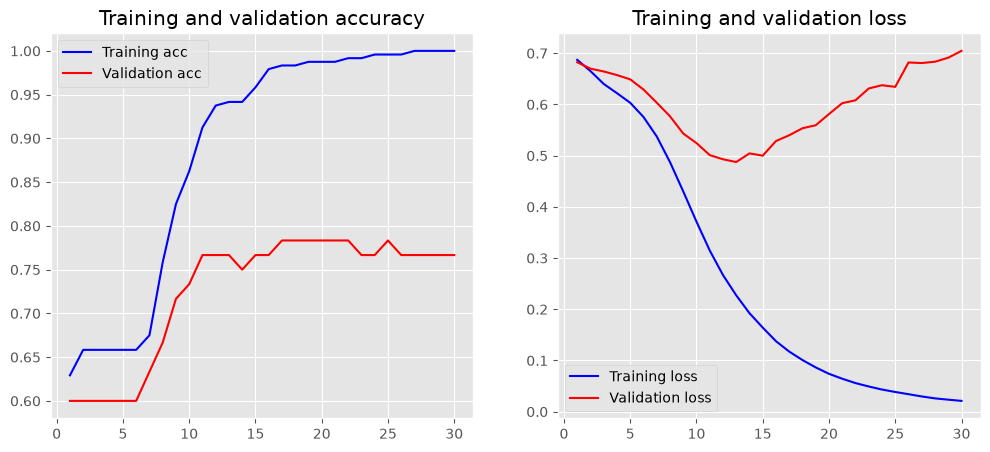

In [91]:
# 📋 الصق هنا صف SimpleTokenizer، وغيّر اسمه إلى ArabicTokenizer، وأضف ،؛؟
class ArabicTokenizer:
    """A small replacement for the old Keras `Tokenizer` (it was removed in Keras 3).
    It turns each word into a whole number. The most frequent word gets 1, the next gets 2, ...
    The number 0 is kept for padding."""

    def __init__(self, num_words=None):
        self.num_words = num_words
        self.word_index = {}      # word -> number
        self.index_word = {}      # number -> word

    @staticmethod
    def _split(text):
        text = text.lower()                                  # lower case
        for ch in '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~؟؛،\t\n':      # remove punctuation
            text = text.replace(ch, ' ')
        for ch in 'أإآ':      # remove punctuation
            text = text.replace(ch, 'ا')
        return [w for w in text.split(' ') if w]             # split into words

    def fit_on_texts(self, texts):
        counts = {}
        for text in texts:
            for w in self._split(text):
                counts[w] = counts.get(w, 0) + 1
        words = sorted(counts, key=counts.get, reverse=True)  # most frequent word first
        self.word_index = {w: i for i, w in enumerate(words, start=1)}
        self.index_word = {i: w for w, i in self.word_index.items()}

    def texts_to_sequences(self, texts):
        sequences = []
        for text in texts:
            seq = []
            for w in self._split(text):
                i = self.word_index.get(w)
                if i is not None and (self.num_words is None or i < self.num_words):
                    seq.append(i)                            # unknown words are skipped
            sequences.append(seq)
        return sequences

    def sequences_to_texts(self, sequences):
        return [' '.join(self.index_word[i] for i in seq if i in self.index_word) for seq in sequences]
    
# TODO: كرر الخطوة 3، الآن مع ArabicTokenizer
# ar_tokenizer = ...
# ...

ar_tokenizer = ArabicTokenizer(num_words=5000)
ar_tokenizer.fit_on_texts(ar_sent_train)
ar_seq_train = ar_tokenizer.texts_to_sequences(ar_sent_train)
ar_seq_test = ar_tokenizer.texts_to_sequences(ar_sent_test)

ar_vocab_size = len(ar_tokenizer.word_index) + 1
ar_maxlen = max(len(s) for s in ar_seq_train)

ar_X_train = pad_sequences(ar_seq_train, padding='post', maxlen=ar_maxlen)
ar_X_test = pad_sequences(ar_seq_test, padding='post', maxlen=ar_maxlen)
print("vocab size:", ar_vocab_size, " maxlen:", ar_maxlen, " train shape:", ar_X_train.shape)
print("vocab size before:", ar_vocab_size_before, " after:", ar_vocab_size, " maxlen:", ar_maxlen)
print("words with Arabic punctuation now:", sum(w[-1] in '،؛؟' for w in ar_tokenizer.word_index))
# TODO 5a: ابنِ نموذجاً ودرّبه 30 حقبة، واحتفظ بـ history، وارسمه بـ plot_history


import numpy as np

ar_model = build_ar_model(ar_vocab_size, ar_maxlen)
ar_history = ar_model.fit(ar_X_train, ar_y_train, epochs=30, verbose=False,
                          validation_split=0.2, batch_size=10)
plot_history(ar_history)

ar_best_epoch = int(np.argmin(ar_history.history['val_loss'])) + 1
print("best epoch:", ar_best_epoch)

ar_final_model = build_ar_model(ar_vocab_size, ar_maxlen)       # NEW model, new random weights
ar_final_model.fit(ar_X_train, ar_y_train, epochs=ar_best_epoch, verbose=False,
                   validation_split=0.2, batch_size=10)
ar_nn_acc = ar_final_model.evaluate(ar_X_test, ar_y_test, verbose=False)[1]
print("Embedding + pooling test accuracy: {:.4f}".format(ar_nn_acc))

In [92]:
# TODO 7a: ابنِ ar_cnn وترجمه واعرض summary() ودرّبه
cnn = Sequential()
cnn.add(layers.Input(shape=(ar_maxlen,), dtype='int32'))
cnn.add(layers.Embedding(ar_vocab_size, 100))
cnn.add(layers.Conv1D(32, 3, activation='relu'))
cnn.add(layers.GlobalMaxPooling1D())
cnn.add(layers.Dense(10, activation='relu'))
cnn.add(layers.Dense(1, activation='sigmoid'))
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.fit(ar_X_train, ar_y_train, epochs=ar_best_epoch, verbose=False, validation_split=0.2, batch_size=10)
ar_cnn_acc = cnn.evaluate(ar_X_test, ar_y_test, verbose=False)[1]           # TODO 7b: دقة الاختبار
print("CNN test accuracy: {:.4f}".format(ar_cnn_acc))
cnn.summary()

CNN test accuracy: 0.8800


Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_25 (Embedding)        │ (None, 19, 100)        │        29,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 17, 32)         │         9,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_24         │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 10)             │           330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 119,021 (464.93 KB)

 Trainable params: 39,673 (154.97 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 79,348 (309.96 KB)

<div dir="rtl" style="text-align:right">

## ✅ قبل التسليم
- [ ] كل الخلايا تعمل من الأعلى إلى الأسفل بدون أخطاء (*Restart and run all*).
- [ ] كل خلية ✏️ فيها إجابتك.
- [ ] الخطوة 8 تعرض الدقات الخمس، واستنتاجك يستخدم **عدد المراجعات**.
- [ ] الخطوة 9 فيها مراجعتك الخاصة.

*ملاحظة عن البيانات: `arabic_food_reviews.csv` مُصطنَعة (صُنعت لهذا التمرين). ليست بيانات عملاء حقيقية.*

</div>

In [93]:
import gensim

# تحميل نموذج Word2Vec المدرّب مسبقاً (AraVec)
aravec_model = gensim.models.Word2Vec.load(ARAVEC_PATH)

# TODO 6a: ar_embedding_matrix = create_embedding_matrix(...)
embedding_dim = 50
ar_embedding_matrix = create_embedding_matrix(
    aravec_model,
    ar_tokenizer.word_index, embedding_dim)
nonzero_elements = np.count_nonzero(np.count_nonzero(ar_embedding_matrix, axis=1))

ar_coverage = nonzero_elements / ar_vocab_size          # TODO 6b
print("AraVec coverage: {:.1%}".format(ar_coverage))

# معطى: أي كلماتنا لها متجه في AraVec؟
covered = [w for w, i in ar_tokenizer.word_index.items() if ar_embedding_matrix[i].any()]
print(len(covered), "words have an AraVec vector:", covered)
# TODO 6c: ابنِ ar_aravec_model (AraVec مجمّد) وترجمه ودرّبه 30 حقبة
ar_aravec_model = Sequential()
ar_aravec_model.add(layers.Input(shape=(ar_maxlen,), dtype='int32'))
ar_aravec_model.add(layers.Embedding(ar_vocab_size, embedding_dim,
                           embeddings_initializer=keras.initializers.Constant(ar_embedding_matrix),
                           trainable=True))
ar_aravec_model.add(layers.GlobalMaxPool1D())
ar_aravec_model.add(layers.Dense(10, activation='relu'))
ar_aravec_model.add(layers.Dense(1, activation='sigmoid'))
ar_aravec_model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
history = ar_aravec_model.fit(ar_X_train, ar_y_train,
                    epochs=30,
                    verbose=False,
                    validation_split = 0.2,
                    batch_size=10)
loss, accuracy = ar_aravec_model.evaluate(ar_X_train, ar_y_train, verbose=False)
ar_aravec_acc = accuracy         # TODO 6d: دقة الاختبار
print("Trained AraVec test accuracy: {:.4f}".format(ar_aravec_acc))

# معطى: ماذا يتوقع هذا النموذج؟
ar_aravec_pred = ar_aravec_model.predict(ar_X_test, verbose=0).ravel() > 0.5
print("share of test reviews predicted positive: {:.2f}".format(ar_aravec_pred.mean()))
print("always-positive test accuracy:            {:.2f}".format(ar_majority_acc))

AraVec coverage: 67.3%
200 words have an AraVec vector: ['طلبت', 'الطلب', 'كان', 'التطبيق', 'وصل', 'ما', 'مو', 'من', 'بطلب', 'كتير', 'تاني', 'اليوم', 'والله', 'الاكل', 'كل', 'عن', 'طريق', 'فيه', 'رقم', 'و', 'عشا', 'التوصيل', 'سريع', 'باسم', 'احمد', 'رح', 'شي', 'ونظيف', 'التغليف', 'بس', 'مرتب', 'اول', 'بجرب', 'شوي', 'يعطيكم', 'لذيذ', 'لكن', 'متل', 'كامل', 'اكيد', 'اطلب', 'السعر', 'محترم', 'معقول', 'والاكل', 'اونلاين', 'طازج', 'لاول', 'هالمطعم', 'سيء', 'وطلبت', 'المندوب', 'مستوي', 'انصح', 'البيتزا', 'بارد', 'الطعام', 'وصلت', 'ولطيف', 'الطعم', 'تاخر', 'تسلم', 'ايدكم', 'فرع', 'سخن', 'الفروج', 'تمام', 'قبل', 'لاربع', 'اشخاص', 'بالاكل', 'البرغر', 'بيعلق', 'مشاوي', 'غلط', 'والطلب', 'سهل', 'دفعت', 'اسرع', 'المتوقع', 'غالي', 'شاورما', 'وبطاطا', 'والبيتزا', 'والتطبيق', 'وسريع', 'الوقت', 'العيد', 'خيارات', 'والصوص', 'رائع', 'اكل', 'البيت', 'والسعر', 'عم', 'مضبوط', 'كانت', 'والتوصيل', 'انحلت', 'لليوم', 'نجوم', 'والدفع', 'عند', 'الباب', 'مريح', 'والطعم', 'الكم', 'بنصح', 'بالوقت', 'ناقص', 'الدفع', '